In [ ]:

import theano
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time
import keras
from tensorflow.keras import layers
from tensorflow.keras import models
import random
from __future__ import division
from __future__ import print_function
from keras.layers import Dense, Dropout, Activation, Flatten
from keras import optimizers
from keras import backend as K
from keras.utils import np_utils
from keras import regularizers
from keras.regularizers import Regularizer
from keras.regularizers import l1, l2

In [ ]:
#@title 默认标题文本
from google.colab import drive
drive.mount('/content/drive', force_remount=True)




Mounted at /content/drive


Part 1, load and transform data

In [ ]:
#train = np.loadtxt('/content/drive/My Drive/data/train.dat')
#label=np.loadtxt('/content/drive/My Drive/data/label.dat')

import csv

with open('/content/drive/My Drive/data/samX.csv') as csvfile:
    readCSV = csv.reader(csvfile, delimiter=',')
    train=[]
    count=0
    for row in readCSV:
      if count>=1:
        train.append(row[1:])
      count+=1
with open('/content/drive/My Drive/data/samY.csv') as csvfile:
    readCSV = csv.reader(csvfile, delimiter=',')
    label=[]
    count=0
    for row in readCSV:
      if count>=1:
        label.append(row[1:])
      count+=1





# 新段落

In [ ]:
train=np.array(train)
label=np.array(label)
train=train.astype('float32')
label=label.astype('float32')
print(train.shape)
print(label.shape)

(10000, 600)
(10000, 4)


In [ ]:

train=train.reshape((10000,600,1))
print(train.shape)
#train=train+0.05*random.uniform(0, 1)


(10000, 600, 1)


In [ ]:
trainx=train[2000:]

testx=train[:2000]
testy=label[:2000]
testylis=[]
testylis.append(testy[:,0:1])
testylis.append(testy[:,1:2])
testylis.append(testy[:,2:3])
testylis.append(testy[:,3:4])
print(testx.shape)
print(testylis[1].shape)

(2000, 600, 1)
(2000, 1)


In [ ]:
lbs=[]
lbs.append(label[2000:,0:1])
lbs.append(label[2000:,1:2])
lbs.append(label[2000:,2:3])
lbs.append(label[2000:,3:4])


Part 2. initialize variable and define sparse functions

In [ ]:
epsilon = 20 # control the sparsity level as discussed in the paper
zeta = 0.3 # the fraction of the weights removed



class Constraint(object):

    def __call__(self, w):
        return w

    def get_config(self):
        return {}

class MaskWeights(Constraint):

    def __init__(self, mask):
        self.mask = mask
        self.mask = K.cast(self.mask, K.floatx())

    def __call__(self, w):
        w =w* self.mask
        return w

    def get_config(self):
        return {'mask': self.mask}
def find_first_pos(array, value):
    idx = (np.abs(array - value)).argmin()
    return idx


def find_last_pos(array, value):
    idx = (np.abs(array - value))[::-1].argmin()
    return array.shape[0] - idx
def rewireMask(weights, noWeights):
        # rewire weight matrix

        # remove zeta largest negative and smallest positive weights
        values = np.sort(weights.ravel())
        firstZeroPos = find_first_pos(values, 0)
        lastZeroPos = find_last_pos(values, 0)
        largestNegative = values[int((1-zeta) * firstZeroPos)]
        smallestPositive = values[int(min(values.shape[0] - 1, lastZeroPos +zeta * (values.shape[0] - lastZeroPos)))]
        rewiredWeights = weights.copy();
        rewiredWeights[rewiredWeights > smallestPositive] = 1;
        rewiredWeights[rewiredWeights < largestNegative] = 1;
        rewiredWeights[rewiredWeights != 1] = 0;
        weightMaskCore = rewiredWeights.copy()

        # add zeta random weights
        nrAdd = 0
        noRewires = noWeights - np.sum(rewiredWeights)
        while (nrAdd < noRewires):
            i = np.random.randint(0, rewiredWeights.shape[0])
            j = np.random.randint(0, rewiredWeights.shape[1])
            if (rewiredWeights[i, j] == 0):
                rewiredWeights[i, j] = 1
                nrAdd += 1

        return [rewiredWeights, weightMaskCore]


def createWeightsMask(epsilon,noRows, noCols):
    # generate an Erdos Renyi sparse weights mask
    mask_weights = np.random.rand(noRows, noCols)
    prob = 1 - (epsilon * (noRows + noCols)) / (noRows * noCols)  # normal tp have 8x connections
    mask_weights[mask_weights < prob] = 0
    mask_weights[mask_weights >= prob] = 1
    noParameters = np.sum(mask_weights)
    print ("Create Sparse Matrix: No parameters, NoRows, NoCols ",noParameters,noRows,noCols)
    return [noParameters,mask_weights]


Part 3 train models

In [ ]:
def count_neurons(model):
    return np.sum([np.sum(np.sum(np.abs(l.get_weights()[0]), axis=1) > 10**-3) \
                          for l in model.layers])

class TrainHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.losses = []
        self.neurons = [count_neurons(self.model)]

    def on_batch_end(self, batch, logs={}):
        self.losses.append(logs.get('loss'))
        self.neurons.append(count_neurons(self.model))

class L21(Regularizer):
    """Regularizer for L21 regularization.
    # Arguments
        C: Float; L21 regularization factor.
    """

    def __init__(self, C=0.):
        self.C = K.cast_to_floatx(C)

    def __call__(self, x):
        const_coeff = np.sqrt(K.int_shape(x)[1])
        return self.C*const_coeff*K.sum(K.sqrt(K.sum(K.square(x), axis=1)))

    def get_config(self):
        return {'C': float(self.l1)}


In [ ]:
# normal DNN model

def create_nonconv_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.BatchNormalization()(li)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid')(output)
  model=models.Model(inputs=li, outputs=output)
  return model

DNNmodel=[]
DNNmodel.append(create_nonconv_model(600))
DNNmodel.append(create_nonconv_model(600))
DNNmodel.append(create_nonconv_model(600))
DNNmodel.append(create_nonconv_model(600))
DNNhis=[]
start_time = time.time()
for i in range(4):

  DNNmodel[i].compile(optimizer='sgd',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  DNNhis.append(DNNmodel[i].fit(train,lbs[i],epochs=50))
print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/50
313/313 [==============================] - 3s 4ms/step - loss: 0.2494 - accuracy: 0.6225 - mean_absolute_error: 0.4151 - recall: 0.5750 - precision: 0.6262
Epoch 2/50
313/313 [==============================] - 1s 4ms/step - loss: 0.2308 - accuracy: 0.6407 - mean_absolute_error: 0.4126 - recall: 0.6143 - precision: 0.6320
Epoch 3/50
313/313 [==============================] - 1s 3ms/step - loss: 0.2202 - accuracy: 0.6433 - mean_absolute_error: 0.4141 - recall: 0.6129 - precision: 0.6460
Epoch 4/50
313/313 [==============================] - 1s 4ms/step - loss: 0.2157 - accuracy: 0.6471 - mean_absolute_error: 0.4167 - recall: 0.6121 - precision: 0.6431
Epoch 5/50
313/313 [==============================] - 1s 4ms/step - loss: 0.2124 - accuracy: 0.6538 - mean_absolute_error: 0.4144 - recall: 0.6284 - precision: 0.6682
Epoch 6/50
313/313 [==============================] - 1s 4ms/step - loss: 0.2134 - accuracy: 0.6559 - mean_absolute_error: 0.4174 - recall: 0.6059 - precision: 0.657

In [ ]:
lambda_val = .7

# normal las DNN model

def create_nonconv_lasso_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.BatchNormalization()(li)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid',kernel_regularizer = l1(lambda_val))(output)
  model=models.Model(inputs=li, outputs=output)
  return model

DNNlasmodel=[]
DNNlasmodel.append(create_nonconv_lasso_model(600))
DNNlasmodel.append(create_nonconv_lasso_model(600))
DNNlasmodel.append(create_nonconv_lasso_model(600))
DNNlasmodel.append(create_nonconv_lasso_model(600))
DNNlashis=[]
start_time = time.time()
for i in range(4):

  DNNlasmodel[i].compile(optimizer='adam',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  DNNlashis.append(DNNlasmodel[i].fit(train,lbs[i],epochs=50))

print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/50
313/313 [==============================] - 2s 4ms/step - loss: 5.0968 - accuracy: 0.6252 - mean_absolute_error: 0.4148 - recall: 0.5747 - precision: 0.6310
Epoch 2/50
313/313 [==============================] - 1s 4ms/step - loss: 0.2477 - accuracy: 0.6032 - mean_absolute_error: 0.4718 - recall: 0.3911 - precision: 0.6936
Epoch 3/50
313/313 [==============================] - 1s 4ms/step - loss: 0.2296 - accuracy: 0.6543 - mean_absolute_error: 0.4333 - recall: 0.6183 - precision: 0.6578
Epoch 4/50
118/313 [==========>...................] - ETA: 0s - loss: 0.2275 - accuracy: 0.6547 - mean_absolute_error: 0.4290 - recall: 0.6118 - precision: 0.6607

KeyboardInterrupt: ignored

In [ ]:

# normal group las DNN model

def create_nonconv_group_lasso_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.BatchNormalization()(li)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid',kernel_regularizer=L21(0.001))(output)
  model=models.Model(inputs=li, outputs=output)
  return model

DNNgrouplasmodel=[]
DNNgrouplasmodel.append(create_nonconv_group_lasso_model(600))
DNNgrouplasmodel.append(create_nonconv_group_lasso_model(600))
DNNgrouplasmodel.append(create_nonconv_group_lasso_model(600))
DNNgrouplasmodel.append(create_nonconv_group_lasso_model(600))
DNNgrouplashis=[]
nehis=[]
start_time = time.time()
for i in range(4):

  DNNgrouplasmodel[i].compile(optimizer='adam',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  DNNgrouplashis.append(DNNgrouplasmodel[i].fit(train,lbs[i],epochs=50))
  nehis.append(TrainHistory())

print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/50


InvalidArgumentError: ignored

In [ ]:
# SET DNN
def weightsEvolution(model):
# this represents the core of the SET procedure. It removes the weights closest to zero in each layer and add new random weights

    bat=model.get_layer("bat_layer").get_weights()
    w2=model.get_layer("dense_layer2").get_weights()
    w1 = model.get_layer("dense_layer1").get_weights()
    
    [wm1, wm1Core] = rewireMask(w1[0], noPar1)

    w1[0] = w1[0] * wm1Core
    return bat,w1,w2,wm1

def create_SET_nonconv_model(windowsize,bat,w1,w2,wm1):
  li=layers.Input((windowsize,1))
  x=layers.BatchNormalization(name='bat_layer',weights=bat)(li)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100,name='dense_layer1',kernel_constraint=MaskWeights(wm1),weights=w1)(x)
  output=layers.Dense(1,activation='sigmoid',name='dense_layer2',weights=w2)(output)
  model=models.Model(inputs=li, outputs=output)
  return model


SETDNNmodel=[]
SETDNNhis=[]
start_time = time.time()
for i in range(4):
  SETDNNhis.append({})
  [noPar1, wm1] = createWeightsMask(epsilon,600,100)
  w1=None
  w2=None
  bat=None
  SETDNNmodel.append(create_SET_nonconv_model(600,bat,w1,w2,wm1))
  for j in range(200):

    SETDNNmodel[i].compile(loss='mean_squared_error', optimizer='sgd', metrics=['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
    historytemp = SETDNNmodel[i].fit(train,lbs[0],epochs=1)
    for key in historytemp.history:
      
      if key in SETDNNhis[i]:
        SETDNNhis[i][key].append(historytemp.history[key])
      else:
        SETDNNhis[i][key]=[historytemp.history[key]]
    bat,w1,w2,wm1=weightsEvolution(SETDNNmodel[i])
    K.clear_session()
    
    SETDNNmodel[i]=create_SET_nonconv_model(600,bat,w1,w2,wm1)

  
print("--- %s seconds ---" % (time.time() - start_time))

In [ ]:
#normal 1d CONV 
def create_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu')(li)
  x=layers.Conv1D(64, 2, activation='relu')(x)
  x=layers.BatchNormalization()(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid')(output)
  model=models.Model(inputs=li, outputs=output)
  return model

class TestCallback(keras.callbacks.Callback):
  def __init__(self, test_data):
      self.test_data = test_data
  def on_epoch_end(self, epoch, logs={}):
      x, y = self.test_data
      print(x.shape)
      print(y.shape)
      self.test_time = time.time()
      result = self.model.evaluate(x, y, verbose=1)
      testt=time.time() - self.test_time
      print('\nTesting loss: {}, acc: {}\n'.format(result[0], result[1]))
      print('\nTesting time: {}'.format(testt))
tmodel=[]
tmodel.append(create_model(600))
tmodel.append(create_model(600))
tmodel.append(create_model(600))
tmodel.append(create_model(600))
CONVhis=[]
start_time = time.time()
for i in range(4):

  tmodel[i].compile(optimizer='sgd',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  CONVhis.append(tmodel[i].fit(trainx,lbs[i],epochs=50,callbacks=[TestCallback((testx, testylis[i]))]))

print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/50
250/250 [==============================] - 2s 5ms/step - loss: 0.2068 - accuracy: 0.7380 - mean_absolute_error: 0.2913 - recall: 0.7714 - precision: 0.7162
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 1s 4ms/step - loss: 0.1409 - accuracy: 0.8335 - mean_absolute_error: 0.1909 - recall: 0.7304 - precision: 0.9178

Testing loss: 0.14088410139083862, acc: 0.8335000276565552


Testing time: 0.5590217113494873
Epoch 2/50
250/250 [==============================] - 1s 5ms/step - loss: 0.1046 - accuracy: 0.8732 - mean_absolute_error: 0.1535 - recall: 0.8833 - precision: 0.8619
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 0s 4ms/step - loss: 0.1676 - accuracy: 0.8040 - mean_absolute_error: 0.2078 - recall: 0.6509 - precision: 0.9350

Testing loss: 0.16757845878601074, acc: 0.8040000200271606


Testing time: 0.27153539657592773
Epoch 3/50
250/250 [==============================] - 1s 5ms/step - loss: 0.0935 - accuracy: 0.8895 - mean_absolute_e

In [ ]:
#lasso 1d CONV 
lambda_val=0.7
def create_conv_lasso_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu')(li)
  x=layers.Conv1D(64, 2, activation='relu')(x)
  x=layers.BatchNormalization()(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(1,activation='sigmoid',kernel_regularizer = l1(lambda_val))(output)
  model=models.Model(inputs=li, outputs=output)
  return model


tlasmodel=[]
tlasmodel.append(create_conv_lasso_model(600))
tlasmodel.append(create_conv_lasso_model(600))
tlasmodel.append(create_conv_lasso_model(600))
tlasmodel.append(create_conv_lasso_model(600))
CONVlashis=[]
start_time = time.time()
for i in range(4):

  tlasmodel[i].compile(optimizer='adam',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  CONVlashis.append(tlasmodel[i].fit(trainx,lbs[i],epochs=50,callbacks=[TestCallback((testx, testylis[i]))]))

print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/50
250/250 [==============================] - 2s 5ms/step - loss: 5.4298 - accuracy: 0.7313 - mean_absolute_error: 0.2723 - recall: 0.7976 - precision: 0.6996
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 1s 4ms/step - loss: 0.2318 - accuracy: 0.8405 - mean_absolute_error: 0.3320 - recall: 0.9095 - precision: 0.7979

Testing loss: 0.23180794715881348, acc: 0.840499997138977


Testing time: 0.6196587085723877
Epoch 2/50
250/250 [==============================] - 1s 6ms/step - loss: 0.1917 - accuracy: 0.8411 - mean_absolute_error: 0.2965 - recall: 0.8810 - precision: 0.8120
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 0s 4ms/step - loss: 0.1264 - accuracy: 0.8990 - mean_absolute_error: 0.1689 - recall: 0.9316 - precision: 0.8736

Testing loss: 0.12637139856815338, acc: 0.8989999890327454


Testing time: 0.265474796295166
Epoch 3/50
250/250 [==============================] - 1s 5ms/step - loss: 0.1127 - accuracy: 0.9166 - mean_absolute_erro

In [ ]:
#group lasso 1d CONV 
l21v=0.002
def create_conv_lasso_model(windowsize):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu')(li)
  x=layers.Conv1D(64, 2, activation='relu')(x)
  x=layers.BatchNormalization()(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100)(x)
  output=layers.Dense(20,activation='sigmoid',kernel_regularizer=L21(0.002))(output)
  output=layers.Dense(15,activation='sigmoid',kernel_regularizer=L21(0.002))(output)
  output=layers.Dense(1,activation='sigmoid',kernel_regularizer=L21(0.002))(output)
  model=models.Model(inputs=li, outputs=output)
  return model


cnngrouplasmodel=[]
cnngrouplasmodel.append(create_conv_lasso_model(600))
cnngrouplasmodel.append(create_conv_lasso_model(600))
cnngrouplasmodel.append(create_conv_lasso_model(600))
cnngrouplasmodel.append(create_conv_lasso_model(600))
CONVgrouplashis=[]
start_time = time.time()
for i in range(4):

  cnngrouplasmodel[i].compile(optimizer='adam',loss='mean_squared_error',metrics= ['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
  CONVgrouplashis.append(cnngrouplasmodel[i].fit(trainx,lbs[i],epochs=50,callbacks=[TestCallback((testx, testylis[i]))]))

print("--- %s seconds ---" % (time.time() - start_time))

Epoch 1/50
250/250 [==============================] - 3s 6ms/step - loss: 0.6608 - accuracy: 0.7635 - mean_absolute_error: 0.4102 - recall: 0.8227 - precision: 0.7265
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 1s 4ms/step - loss: 0.3704 - accuracy: 0.6000 - mean_absolute_error: 0.4335 - recall: 0.2093 - precision: 0.9369

Testing loss: 0.3704209625720978, acc: 0.6000000238418579


Testing time: 0.6591389179229736
Epoch 2/50
250/250 [==============================] - 2s 6ms/step - loss: 0.1932 - accuracy: 0.9111 - mean_absolute_error: 0.2714 - recall: 0.8984 - precision: 0.9187
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 0s 4ms/step - loss: 0.1645 - accuracy: 0.9180 - mean_absolute_error: 0.2490 - recall: 0.8984 - precision: 0.9341

Testing loss: 0.16452425718307495, acc: 0.9179999828338623


Testing time: 0.29320335388183594
Epoch 3/50
250/250 [==============================] - 2s 6ms/step - loss: 0.1537 - accuracy: 0.9306 - mean_absolute_er

In [ ]:
8

8

In [ ]:
#SET CONV CNN
class TimeHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.times = []

    def on_epoch_begin(self, batch, logs={}):
        self.epoch_time_start = time.time()

    def on_epoch_end(self, batch, logs={}):
        self.times.append(time.time() - self.epoch_time_start)
import gc
def weightsEvolution(model):
        # this represents the core of the SET procedure. It removes the weights closest to zero in each layer and add new random weights
    lconv1=model.get_layer("conv_layer1").get_weights()
    lconv2=model.get_layer("conv_layer2").get_weights()
    bat=model.get_layer("bat_layer").get_weights()
    w2=model.get_layer("dense_layer2").get_weights()
    w1 = model.get_layer("dense_layer1").get_weights()
    
    [wm1, wm1Core] = rewireMask(w1[0], noPar1)

    w1[0] = w1[0] * wm1Core
    return lconv1,lconv2,bat,w1,w2,wm1

def create_SET_conv_model(windowsize,lconv1,lconv2,bat,w1,w2,wm1):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu',name='conv_layer1',weights=lconv1)(li)
  x=layers.Conv1D(64, 2, activation='relu',name='conv_layer2',weights=lconv2)(x)
  x=layers.BatchNormalization(name='bat_layer',weights=bat)(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100,name='dense_layer1',kernel_constraint=MaskWeights(wm1),weights=w1)(x)
  output=layers.Dense(1,activation='sigmoid',name='dense_layer2',weights=w2)(output)
  model=models.Model(inputs=li, outputs=output)
  return model

SETCONVmodel=[]
SETCONVhis=[]

for i in range(4):
  SETCONVhis.append({})
  [noPar1, wm1] = createWeightsMask(epsilon,19136,100)
  lconv1=None
  lconv2=None
  w1=None
  w2=None
  bat=None
  SETCONVmodel.append(create_SET_conv_model(600,lconv1,lconv2,bat,w1,w2,wm1))
  for j in range(50):
    time_callback = TimeHistory()
    
    SETCONVmodel[i].compile(loss='mean_squared_error', optimizer='sgd', metrics=['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
    start_time = time.time()
    historytemp = SETCONVmodel[i].fit(trainx,lbs[i],epochs=1,callbacks=[TestCallback((testx, testylis[i])),time_callback])
    end_time = time.time()
    times = time_callback.times
    print("--- THE REAL %s seconds ---" % (times))
    for key in historytemp.history:
      
      if key in SETCONVhis[i]:
        SETCONVhis[i][key].append(historytemp.history[key])
      else:
        SETCONVhis[i][key]=[historytemp.history[key]]
    lconv1,lconv2,bat,w1,w2,wm1=weightsEvolution(SETCONVmodel[i])
    K.clear_session()
    gc.collect()

    SETCONVmodel[i]=create_SET_conv_model(600,lconv1,lconv2,bat,w1,w2,wm1)

print("--- %s seconds ---" % (time.time() - start_time))

Create Sparse Matrix: No parameters, NoRows, NoCols  384725.0 19136 100
250/250 [==============================] - 2s 5ms/step - loss: 0.1927 - accuracy: 0.7183 - mean_absolute_error: 0.3494 - recall: 0.7417 - precision: 0.6972
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 1s 4ms/step - loss: 0.1156 - accuracy: 0.8610 - mean_absolute_error: 0.2288 - recall: 0.8722 - precision: 0.8517

Testing loss: 0.11557137966156006, acc: 0.8610000014305115


Testing time: 0.5861594676971436
--- THE REAL [2.679777145385742] seconds ---
250/250 [==============================] - 3s 7ms/step - loss: 0.1142 - accuracy: 0.8537 - mean_absolute_error: 0.2349 - recall: 0.8394 - precision: 0.8506
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 1s 4ms/step - loss: 0.1082 - accuracy: 0.8645 - mean_absolute_error: 0.1983 - recall: 0.9004 - precision: 0.8388

Testing loss: 0.10815250128507614, acc: 0.8644999861717224


Testing time: 0.6245450973510742
--- THE REAL [3.1404271

In [ ]:
#temp SET lasso CONV CNN
class TimeHistory(keras.callbacks.Callback):
    def on_train_begin(self, logs={}):
        self.times = []

    def on_epoch_begin(self, batch, logs={}):
        self.epoch_time_start = time.time()

    def on_epoch_end(self, batch, logs={}):
        self.times.append(time.time() - self.epoch_time_start)
import gc
def weightsEvolution(model):
        # this represents the core of the SET procedure. It removes the weights closest to zero in each layer and add new random weights
    lconv1=model.get_layer("conv_layer1").get_weights()
    lconv2=model.get_layer("conv_layer2").get_weights()
    bat=model.get_layer("bat_layer").get_weights()
    w2=model.get_layer("dense_layer2").get_weights()
    w1 = model.get_layer("dense_layer1").get_weights()
    
    [wm1, wm1Core] = rewireMask(w1[0], noPar1)

    w1[0] = w1[0] * wm1Core
    return lconv1,lconv2,bat,w1,w2,wm1
lambda_val=0.7
def create_SET_lasso_conv_model(windowsize,lconv1,lconv2,bat,w1,w2,wm1):
  li=layers.Input((windowsize,1))
  x=layers.Conv1D(64, 2, activation='relu',name='conv_layer1',weights=lconv1)(li)
  x=layers.Conv1D(64, 2, activation='relu',name='conv_layer2',weights=lconv2)(x)
  x=layers.BatchNormalization(name='bat_layer',weights=bat)(x)
  x=layers.MaxPooling1D(pool_size=2)(x)
  x=layers.Flatten()(x)
  x=layers.Dropout(0.2)(x)
  output=layers.Dense(100,name='dense_layer1',kernel_constraint=MaskWeights(wm1),weights=w1)(x)
  output=layers.Dense(1,activation='sigmoid',name='dense_layer2',weights=w2,kernel_regularizer = l1(lambda_val))(output)
  model=models.Model(inputs=li, outputs=output)
  return model

SETLASSOCONVmodel=[]
SETLASSOCONVhis=[]

for i in range(4):
  SETLASSOCONVhis.append({})
  [noPar1, wm1] = createWeightsMask(epsilon,19136,100)
  lconv1=None
  lconv2=None
  w1=None
  w2=None
  bat=None
  SETLASSOCONVmodel.append(create_SET_lasso_conv_model(600,lconv1,lconv2,bat,w1,w2,wm1))
  for j in range(50):
    time_callback = TimeHistory()
    
    SETLASSOCONVmodel[i].compile(loss='mean_squared_error', optimizer='adam', metrics=['accuracy','mean_absolute_error',tf.keras.metrics.Recall(name='recall'),tf.keras.metrics.Precision(name='precision')])
    start_time = time.time()
    historytemp = SETLASSOCONVmodel[i].fit(trainx,lbs[i],epochs=1,callbacks=[TestCallback((testx, testylis[i])),time_callback])
    end_time = time.time()
    times = time_callback.times
    print("--- THE REAL %s seconds ---" % (times))
    for key in historytemp.history:
      
      if key in SETLASSOCONVhis[i]:
        SETLASSOCONVhis[i][key].append(historytemp.history[key])
      else:
        SETLASSOCONVhis[i][key]=[historytemp.history[key]]
    lconv1,lconv2,bat,w1,w2,wm1=weightsEvolution(SETLASSOCONVmodel[i])
    K.clear_session()
    gc.collect()

    SETLASSOCONVmodel[i]=create_SET_lasso_conv_model(600,lconv1,lconv2,bat,w1,w2,wm1)

print("--- %s seconds ---" % (time.time() - start_time))

Create Sparse Matrix: No parameters, NoRows, NoCols  384203.0 19136 100
250/250 [==============================] - 2s 6ms/step - loss: 4.9977 - accuracy: 0.7630 - mean_absolute_error: 0.2593 - recall: 0.8111 - precision: 0.7408
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 1s 4ms/step - loss: 0.2280 - accuracy: 0.8140 - mean_absolute_error: 0.4060 - recall: 0.8089 - precision: 0.8154

Testing loss: 0.22796422243118286, acc: 0.8140000104904175


Testing time: 0.5610482692718506
--- THE REAL [2.8233144283294678] seconds ---
250/250 [==============================] - 3s 7ms/step - loss: 0.1823 - accuracy: 0.8575 - mean_absolute_error: 0.3051 - recall: 0.8071 - precision: 0.8958
(2000, 600, 1)
(2000, 1)
63/63 [==============================] - 1s 4ms/step - loss: 0.1566 - accuracy: 0.8545 - mean_absolute_error: 0.2374 - recall: 0.7465 - precision: 0.9501

Testing loss: 0.15662027895450592, acc: 0.8544999957084656


Testing time: 0.566993236541748
--- THE REAL [3.2775113

In [ ]:
for item in CONVhis[0].history:
  print(item)

loss
accuracy
mean_absolute_error
recall
precision


Create Sparse Matrix: No parameters, NoRows, NoCols  384337.0 19136 100


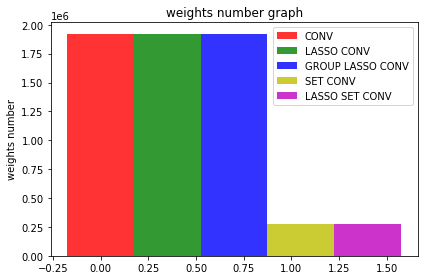

In [ ]:
bar_width = 0.35
opacity = 0.8
a2,b=createWeightsMask(epsilon,19136,100)
index = np.arange(4)

fig, ax = plt.subplots()

def countWeight(model):
  weight_count=[]
  for var in model.trainable_variables:
    weight_count.append(tf.math.count_nonzero(var))
  return np.sum(weight_count)


conv_weight=countWeight(tmodel[0])
las_conv_weight=countWeight(tlasmodel[0])
group_conv_weight=countWeight(cnngrouplasmodel[0])
set_conv_weight=countWeight(SETCONVmodel[0])
set_LASSO_conv_weight=countWeight(SETLASSOCONVmodel[0])

rects1 = plt.bar(0, conv_weight, bar_width,
alpha=opacity,
color='red',
label='CONV')

rects2 = plt.bar(bar_width, las_conv_weight, bar_width,
alpha=opacity,
color='g',
label='LASSO CONV')


rects3 = plt.bar(bar_width*2, group_conv_weight, bar_width,
alpha=opacity,
color='b',
label='GROUP LASSO CONV')

rects4 = plt.bar(bar_width*3, set_conv_weight, bar_width,
alpha=opacity,
color='y',
label='SET CONV')

rects4 = plt.bar(bar_width*4, set_LASSO_conv_weight, bar_width,
alpha=opacity,
color='m',
label='LASSO SET CONV')

plt.ylabel('weights number')
plt.title('weights number graph')
#plt.xticks(index + bar_width, ('washing machine', 'dish washer', 'fridage', 'micromwave'))
plt.legend()

plt.tight_layout()
plt.savefig('conv_weights.png', dpi=1200)
plt.show()

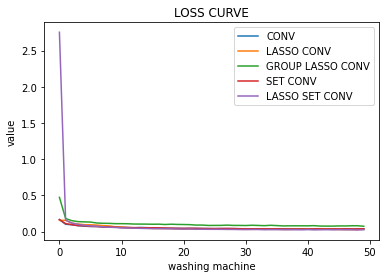

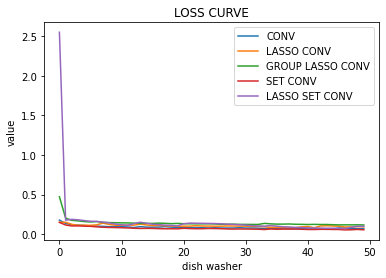

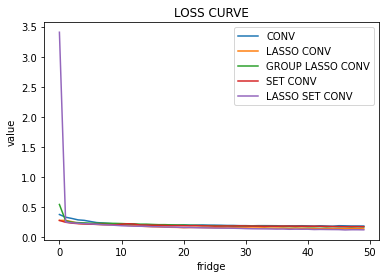

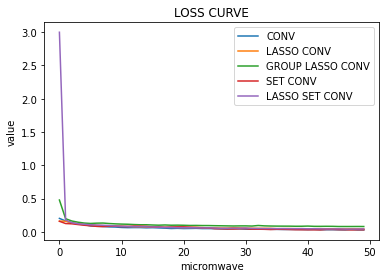

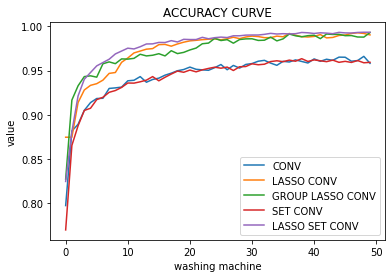

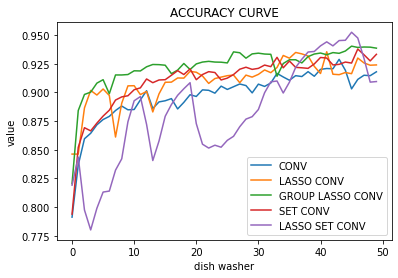

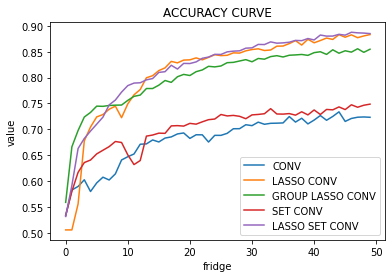

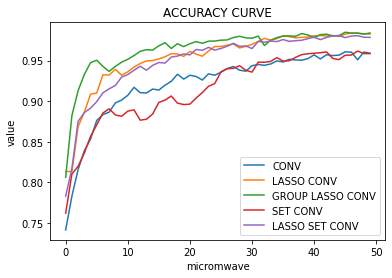

In [ ]:
gn=['loss','accuracy']
device=['washing machine', 'dish washer', 'fridge', 'micromwave']

for i in range(2):
  for j in range(4):
    index=range(50)
    CONVlashis[j].history[gn[i]][0]=CONVlashis[j].history[gn[i]][1]
    plt.plot(index,CONVhis[j].history[gn[i]],label='CONV')
    plt.plot(index,CONVlashis[j].history[gn[i]], label='LASSO CONV')
    plt.plot(index,CONVgrouplashis[j].history[gn[i]],label='GROUP LASSO CONV')
    plt.plot(index,SETCONVhis[j][gn[i]],label='SET CONV')
    plt.plot(index,SETLASSOCONVhis[j][gn[i]],label='LASSO SET CONV')
    plt.xlabel(device[j])
    plt.ylabel('value')
    plt.title(gn[i].upper()+' CURVE')
    plt.legend();
    plt.savefig(device[j]+' '+gn[i]+' curve'+'.png', dpi=1200)
    plt.show()

Part 4: plot

NameError: ignored

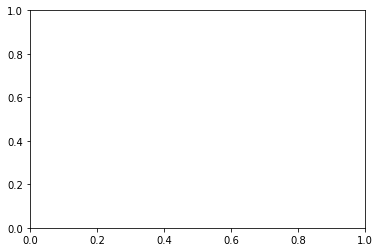

In [ ]:
ms=['DNN','SET DNN','CONV','SET CONV']
device=['washing machine', 'dish washer', 'fridge', 'micromwave']
paras=['loss','acc','mean_absolute_error','recall','precision']
bar_width = 0.35
opacity = 0.8
for i in range(4):
  for j in range(5):

    index = np.arange(4)

    fig, ax = plt.subplots()

    rects1 = plt.bar(0, dh[i][paras[j]][-1], bar_width,
    alpha=opacity,
    color='red',
    label='DNN')

    rects2 = plt.bar(bar_width, sdh[i][paras[j]][-1], bar_width,
    alpha=opacity,
    color='g',
    label='SET DNN')

    rects3 = plt.bar(bar_width*2, ch[i][paras[j]][-1], bar_width,
    alpha=opacity,
    color='b',
    label='CONV')

    rects4 = plt.bar(bar_width*3, sch[i][paras[j]][-1], bar_width,
    alpha=opacity,
    color='y',
    label='SET CONV')

    plt.xlabel(device[i])
    plt.ylabel('value')
    plt.title(paras[j]+' graph')
    #plt.xticks(index + bar_width, ('washing machine', 'dish washer', 'fridage', 'micromwave'))
    plt.legend()

    plt.tight_layout()
    plt.savefig(device[i]+' '+paras[j]+' graph'+'.png', dpi=1200)
    plt.show()

In [ ]:
for j in range(4):
  with open('SETCONVhis'+str(j), 'wb') as file_pi:
        pickle.dump(SETCONVhis[j], file_pi)


In [ ]:
import pickle
for j in range(4):
  with open('DNNh'+str(j), 'wb') as file_pi:
        pickle.dump(DNNhis[j].history, file_pi)
  with open('SETDNNh'+str(j), 'wb') as file_pi:
        pickle.dump(SETDNNhis[j], file_pi)
  with open('CNNh'+str(j), 'wb') as file_pi:
        pickle.dump(CONVhis[j].history, file_pi)

In [ ]:
import pickle
dh=[0]*4
sdh=[0]*4
ch=[0]*4
sch=[0]*4
for j in range(4):
  dh[j] = pickle.load(open('DNNh'+str(j), "rb"))
  sdh[j] = pickle.load(open('SETDNNh'+str(j), "rb"))
  ch[j] = pickle.load(open('CNNh'+str(j), "rb"))
  sch[j] = pickle.load(open('SETCONVhis'+str(j), "rb"))

In [ ]:
gn=['loss','acc']
device=['washing machine', 'dish washer', 'fridge', 'micromwave']

for i in range(2):
  for j in range(4):
    index=range(200)
    plt.plot(index,dh[j][gn[i]],label='DNN')
    plt.plot(index,sdh[j][gn[i]], label='SET DNN')
    plt.plot(index,ch[j][gn[i]],label='CONV')
    plt.plot(index,sch[j][gn[i]],label='SET CONV')
    plt.xlabel(device[j])
    plt.ylabel('value')
    plt.title(gn[i]+' curve')
    plt.legend();
    plt.savefig(device[j]+' '+gn[i]+' curve'+'.png', dpi=1200)
    plt.show()